# Aula 2 — Otimização e Avaliação de Modelos
## Otimização de Hiperparâmetros

Este notebook reconstrói, em ordem lógica e executável célula a célula, o conteúdo dos
slides 9 a 62 da Aula 2. A Aula 1 tratou de **selecionar as features certas**; esta aula
trata de **encontrar os melhores hiperparâmetros** para o modelo já com as features
escolhidas.

**Dataset usado na maior parte da aula:** `make_classification` (sklearn) — dataset
sintético binário com 1000 amostras e 20 features (15 informativas + 5 redundantes). Um
dataset sintético é conveniente aqui porque o foco não é a qualidade dos dados, e sim
comparar *estratégias de busca* de hiperparâmetros de forma controlada.

### Roteiro da aula

1. **Grid Search vs. Random Search** — as duas estratégias clássicas de busca.
2. **Estratégias de validação cruzada** — `StratifiedKFold` e `TimeSeriesSplit`.
3. **Refinamento e diagnóstico** — coarse→fine search, análise de `cv_results_`, overfitting.
4. **Otimização Bayesiana com Optuna** — busca guiada por resultados anteriores, com pruning.
5. **Síntese** — benchmark entre as três famílias e pipeline final de produção.

> **Nota sobre os números da aula original:** alguns slides usam valores altos
> (`n_trials=200`, `n_iter=100`, grades grandes) pensados para um ambiente de produção com
> tempo disponível. Neste notebook, reduzi alguns desses números (sempre indicado no texto)
> para manter o tempo de execução gerenciável — o *código e a lógica* são os mesmos, só a
> escala de busca é menor.
>
> **Nota sobre gaps do material original:** os slides 53 ("RF + pruning") e 55 ("XGBoost com
> early stopping") tinham esses recursos apenas no título — o código de fato não usava
> `trial.report`/`should_prune` nem `early_stopping_rounds`/`eval_set`. Neste notebook eles
> foram implementados de verdade (e o texto explica a diferença).

## 0. Setup do ambiente (slide 17)

Dataset sintético, split treino/teste estratificado. Todas as seções seguintes reaproveitam
`X_train`, `X_test`, `y_train`, `y_test` definidos aqui.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.model_selection import (
    train_test_split, GridSearchCV, RandomizedSearchCV,
    StratifiedKFold, KFold, TimeSeriesSplit, cross_val_score
)
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score
from scipy.stats import uniform, randint, loguniform
import optuna

optuna.logging.set_verbosity(optuna.logging.WARNING)

X, y = make_classification(
    n_samples=1000, n_features=20,
    n_informative=15, n_redundant=5, random_state=42
)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print(f'Treino: {X_train.shape} | Teste: {X_test.shape}')

Treino: (800, 20) | Teste: (200, 20)


---
# Bloco 1 — Grid Search vs. Random Search

As duas estratégias mais básicas de busca de hiperparâmetros: `GridSearchCV` testa **todas**
as combinações de uma grade fixa; `RandomizedSearchCV` amostra um número fixo de combinações
de **distribuições**, o que escala muito melhor quando o espaço de busca é grande.

## 1.1 Dica: escala logarítmica (slide 9)

Hiperparâmetros como `C` (SVM) ou `learning_rate` afetam o modelo de forma **multiplicativa**,
não aditiva — a diferença entre `C=0.001` e `C=0.01` importa tanto quanto entre `C=100` e
`C=1000`. Uma grade linear (`[0.001, 1, 2, 3, ..., 1000]`) desperdiça quase todos os pontos
numa região pouco informativa. Uma grade **logarítmica** (`[0.001, 0.01, 0.1, 1, 10, 100,
1000]`) cobre todas as ordens de magnitude com poucos pontos.

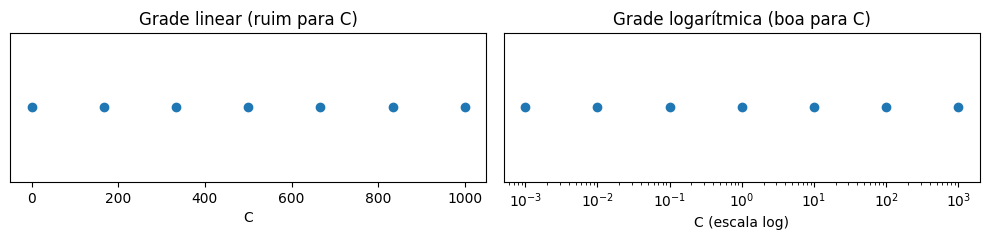

Grade linear: [   0.   166.7  333.3  500.   666.7  833.3 1000. ]
Grade log:    [1.e-03 1.e-02 1.e-01 1.e+00 1.e+01 1.e+02 1.e+03]


In [2]:
# Comparação visual: grade linear vs. grade log cobrindo o mesmo intervalo [0.001, 1000]
linear_grid = np.linspace(0.001, 1000, 7)
log_grid = np.logspace(-3, 3, 7)  # 10^-3 até 10^3, 7 pontos

fig, axes = plt.subplots(1, 2, figsize=(10, 2.5))
axes[0].scatter(linear_grid, [0]*len(linear_grid))
axes[0].set_title('Grade linear (ruim para C)')
axes[0].set_xlabel('C')
axes[0].set_yticks([])

axes[1].scatter(log_grid, [0]*len(log_grid))
axes[1].set_xscale('log')
axes[1].set_title('Grade logarítmica (boa para C)')
axes[1].set_xlabel('C (escala log)')
axes[1].set_yticks([])

plt.tight_layout()
plt.show()

print('Grade linear:', np.round(linear_grid, 1))
print('Grade log:   ', np.round(log_grid, 3))

# Para RandomizedSearchCV, o equivalente contínuo é loguniform (em vez de uniform)
param_dist_example = {'C': loguniform(0.001, 1000)}

## 1.2 GridSearchCV: implementação (slide 18)

Busca exaustiva: testa **todas** as combinações da grade com validação cruzada (5-fold).
Com 4 valores de `C` × 2 de `kernel` × 4 de `gamma` = 32 combinações × 5 folds = 160 ajustes
de modelo.

In [4]:
param_grid = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['rbf', 'poly'],
    'gamma': ['scale', 'auto', 0.01, 0.1]
}

grid_search = GridSearchCV(
    SVC(), param_grid, cv=5,
    scoring='accuracy', n_jobs=-1, verbose=0
)
grid_search.fit(X_train, y_train)

print(f'Melhor score: {grid_search.best_score_:.4f}')
print(f'Melhores HPs: {grid_search.best_params_}')
print(f'Combinações testadas: {len(grid_search.cv_results_["params"])}')

Melhor score: 0.9450
Melhores HPs: {'C': 10, 'gamma': 0.01, 'kernel': 'rbf'}
Combinações testadas: 32


## 1.3 RandomizedSearchCV: implementação (slide 19)

Em vez de listas fixas, definimos **distribuições** (`loguniform` para `C` e `gamma`, seguindo
a dica do slide 9). `RandomizedSearchCV` amostra um número fixo de combinações — aqui usamos
`n_iter=30` (o slide original usa 50; reduzido só para manter o notebook rápido).

In [3]:
param_dist = {
    'C': loguniform(0.01, 1000),
    'kernel': ['rbf', 'poly', 'sigmoid'],
    'gamma': loguniform(0.0001, 10),
}

random_search = RandomizedSearchCV(
    SVC(), param_dist, n_iter=30, cv=5,
    scoring='accuracy', n_jobs=-1,
    random_state=42, verbose=0
)
random_search.fit(X_train, y_train)

print(f'Melhor score: {random_search.best_score_:.4f}')
print(f'Melhores HPs: {random_search.best_params_}')

Melhor score: 0.9113
Melhores HPs: {'C': np.float64(0.8777815504719655), 'gamma': np.float64(0.002273762810253686), 'kernel': 'rbf'}


## 1.4 Comparando resultados (slide 20)

Grid testou 32 combinações fixas; Random testou 30 combinações amostradas de distribuições
contínuas — com um espaço de busca maior (mais valores possíveis de `gamma`/`C`) e menos
avaliações. Compare o `best_score_` (CV) e o score real no teste dos dois.

In [5]:
print('=== Grid Search ===')
print(f'Melhor CV score: {grid_search.best_score_:.4f}')
print(f'Score no teste:  {grid_search.score(X_test, y_test):.4f}')

print('\n=== Random Search ===')
print(f'Melhor CV score: {random_search.best_score_:.4f}')
print(f'Score no teste:  {random_search.score(X_test, y_test):.4f}')

y_pred = random_search.predict(X_test)
print('\n', classification_report(y_test, y_pred))

=== Grid Search ===
Melhor CV score: 0.9450
Score no teste:  0.9600

=== Random Search ===
Melhor CV score: 0.9113
Score no teste:  0.9200

               precision    recall  f1-score   support

           0       0.93      0.91      0.92       100
           1       0.91      0.93      0.92       100

    accuracy                           0.92       200
   macro avg       0.92      0.92      0.92       200
weighted avg       0.92      0.92      0.92       200



---
# Bloco 2 — Estratégias de validação cruzada

A qualidade da busca de hiperparâmetros depende de como os folds de CV são construídos.
Aqui vemos duas estratégias além do `KFold` padrão.

## 2.1 Stratified K-Fold (slide 30)

`StratifiedKFold` mantém a **proporção de classes** em cada fold — essencial quando as
classes são desbalanceadas (sem isso, um fold pode ficar com poucas ou nenhuma amostra da
classe minoritária, distorcendo a métrica de validação).

In [6]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_skf = GridSearchCV(
    SVC(), param_grid, cv=skf,
    scoring='accuracy', n_jobs=-1
)
grid_skf.fit(X_train, y_train)
print(f'Melhor score (com StratifiedKFold): {grid_skf.best_score_:.4f}')

scores = cross_val_score(SVC(C=1), X_train, y_train, cv=skf)
print(f'Scores: {np.round(scores, 4)}')
print(f'Média: {scores.mean():.4f} ± {scores.std():.4f}')

Melhor score (com StratifiedKFold): 0.9400
Scores: [0.8938 0.9375 0.9375 0.9188 0.925 ]
Média: 0.9225 ± 0.0161


## 2.2 Time Series Split (slide 31)

Em dados temporais, um `KFold` comum embaralha o tempo — o modelo acaba "vendo o futuro"
durante a validação (leakage temporal). `TimeSeriesSplit` garante que a validação é sempre
**posterior** ao treino em cada fold.

> **Atenção:** `X_train` aqui é um dataset sintético **sem ordem temporal real** — usamos
> só para mostrar a mecânica do `TimeSeriesSplit` (como os índices de treino crescem e a
> validação sempre vem depois). Para um caso de uso real, veja a disciplina "Séries
> Temporais" desta mesma fase.

In [7]:
tscv = TimeSeriesSplit(n_splits=5)

for fold, (train_idx, val_idx) in enumerate(tscv.split(X_train)):
    print(f'Fold {fold}: treino[0:{train_idx[-1]}] -> val[{val_idx[0]}:{val_idx[-1]}]')

grid_ts = GridSearchCV(SVC(), param_grid, cv=tscv, scoring='accuracy', n_jobs=-1)
grid_ts.fit(X_train, y_train)
print(f'\nMelhor score (TimeSeriesSplit): {grid_ts.best_score_:.4f}')

Fold 0: treino[0:134] -> val[135:267]
Fold 1: treino[0:267] -> val[268:400]
Fold 2: treino[0:400] -> val[401:533]
Fold 3: treino[0:533] -> val[534:666]
Fold 4: treino[0:666] -> val[667:799]

Melhor score (TimeSeriesSplit): 0.9173


## 2.3 Pipeline completo: GridSearchCV com Random Forest (slide 32)

Grade de hiperparâmetros do Random Forest, com `StratifiedKFold` e
`return_train_score=True` (necessário para o diagnóstico de overfitting do próximo bloco).

> Grade reduzida em relação ao slide original (`n_estimators` até 200 em vez de 500,
> `max_depth` com 3 opções em vez de 4) só para manter o tempo de execução razoável.

In [8]:
rf = RandomForestClassifier(random_state=42)
param_grid_rf = {
    'n_estimators': [100, 200],
    'max_depth': [5, 10, None],
    'min_samples_split': [2, 10],
    'max_features': ['sqrt', 'log2']
}

grid_rf = GridSearchCV(
    rf, param_grid_rf, cv=skf,
    scoring='accuracy', n_jobs=-1, verbose=0,
    return_train_score=True
)
grid_rf.fit(X_train, y_train)
print(f'Total combinações: {len(grid_rf.cv_results_["params"])}')
print(f'Melhor score CV: {grid_rf.best_score_:.4f}')
print(f'Score teste: {grid_rf.score(X_test, y_test):.4f}')

Total combinações: 24
Melhor score CV: 0.9075
Score teste: 0.9250


## 2.4 RandomizedSearchCV com Random Forest (slide 33)

Mesmo modelo, agora com distribuições contínuas (`randint`) em vez de grade fixa —
`n_iter=30` (slide original usa 100).

In [9]:
param_dist_rf = {
    'n_estimators': randint(50, 300),
    'max_depth': [5, 10, 20, 30, None],
    'min_samples_split': randint(2, 20),
    'min_samples_leaf': randint(1, 10),
    'max_features': ['sqrt', 'log2', None]
}

random_rf = RandomizedSearchCV(
    RandomForestClassifier(random_state=42),
    param_dist_rf, n_iter=30, cv=skf,
    scoring='accuracy', n_jobs=-1,
    random_state=42, verbose=0
)
random_rf.fit(X_train, y_train)
print(f'Melhor score CV: {random_rf.best_score_:.4f}')
print(f'Melhores HPs: {random_rf.best_params_}')

Melhor score CV: 0.9075
Melhores HPs: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 11, 'n_estimators': 269}


---
# Bloco 3 — Refinamento e diagnóstico

Como refinar a busca depois de uma primeira rodada, e como usar `cv_results_` para entender
*por que* certos hiperparâmetros funcionaram melhor.

## 3.1 Coarse → Fine search (slide 37)

Estratégia em duas etapas: uma busca ampla (grade espaçada em escala log) para achar a
**região** promissora, seguida de uma busca fina (grade linear e estreita) ao redor do
melhor ponto encontrado.

In [11]:
# ETAPA 1: busca ampla
param_coarse = {
    'C': [0.01, 0.1, 1, 10, 100, 1000],
    'gamma': [0.0001, 0.001, 0.01, 0.1, 1]
}
grid_coarse = GridSearchCV(SVC(), param_coarse, cv=5, n_jobs=-1)
grid_coarse.fit(X_train, y_train)
best_C = grid_coarse.best_params_['C']
best_gamma = grid_coarse.best_params_['gamma']
print(f'Melhor região: C={best_C}, gamma={best_gamma}')

# ETAPA 2: refinamento ao redor do melhor ponto (zoom proporcional, funciona para qualquer C/gamma)
param_fine = {
    'C': sorted({round(best_C * f, 5) for f in [0.5, 0.75, 1.0, 1.5, 2.0]}),
    'gamma': sorted({round(best_gamma * f, 6) for f in [0.5, 0.75, 1.0, 1.5, 2.0]}),
}
grid_fine = GridSearchCV(SVC(), param_fine, cv=5, n_jobs=-1)
grid_fine.fit(X_train, y_train)
print(f'Refinado: {grid_fine.best_params_}')
print(f'Score: {grid_fine.best_score_:.4f} (coarse: {grid_coarse.best_score_:.4f})')

Melhor região: C=10, gamma=0.01
Refinado: {'C': 5.0, 'gamma': 0.015}
Score: 0.9525 (coarse: 0.9450)


## 3.2 Analisando resultados do GridSearchCV (slide 38)

`cv_results_` guarda o resultado de **todas** as combinações testadas, não só a melhor.
Comparando `mean_train_score` com `mean_test_score` conseguimos diagnosticar overfitting:
um gap grande indica que o modelo decora o treino e generaliza mal.

In [12]:
results = pd.DataFrame(grid_rf.cv_results_)
results = results.sort_values('rank_test_score')

print(results[[
    'params', 'mean_test_score', 'std_test_score',
    'mean_train_score', 'rank_test_score'
]].head())

results['gap'] = results['mean_train_score'] - results['mean_test_score']
print(f'\nGap médio treino-validação: {results["gap"].mean():.4f}')
if results['gap'].mean() > 0.05:
    print('Possível overfitting - considere regularizar!')
else:
    print('Gap pequeno - sem sinal forte de overfitting nesta grade.')

                                               params  mean_test_score  \
20  {'max_depth': None, 'max_features': 'log2', 'm...          0.90750   
21  {'max_depth': None, 'max_features': 'log2', 'm...          0.90750   
17  {'max_depth': None, 'max_features': 'sqrt', 'm...          0.90750   
16  {'max_depth': None, 'max_features': 'sqrt', 'm...          0.90750   
12  {'max_depth': 10, 'max_features': 'log2', 'min...          0.90375   

    std_test_score  mean_train_score  rank_test_score  
20        0.019121               1.0                1  
21        0.016008               1.0                1  
17        0.016008               1.0                1  
16        0.019121               1.0                1  
12        0.012870               1.0                5  

Gap médio treino-validação: 0.0947
Possível overfitting - considere regularizar!


## 3.3 Visualizando a importância dos hiperparâmetros (slide 39)

Agrupamos os resultados por valor de cada hiperparâmetro e olhamos o score médio — dá para
ver visualmente quais parâmetros mais afetam a performance.

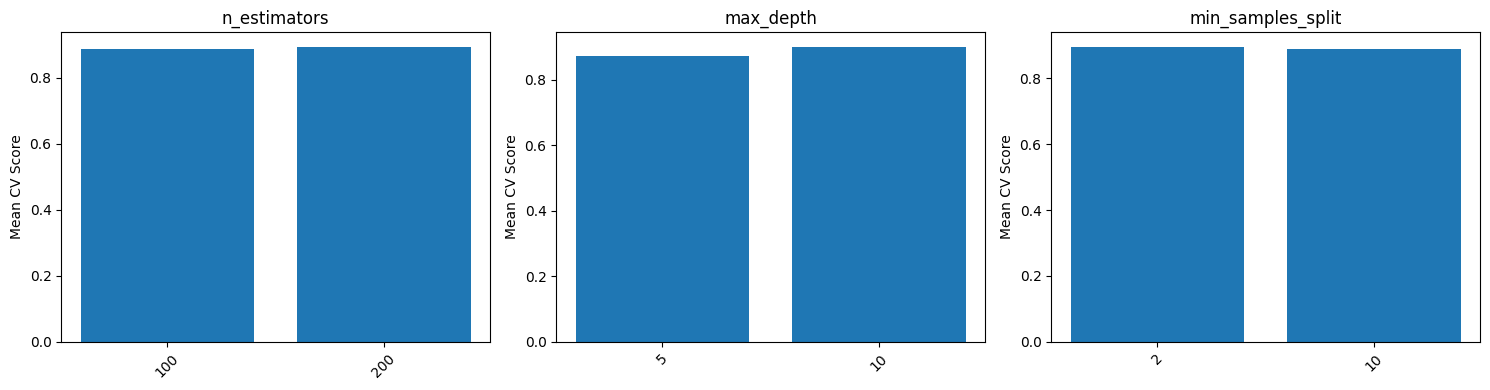

In [13]:
results = pd.DataFrame(grid_rf.cv_results_)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, param in zip(axes, ['param_n_estimators',
                             'param_max_depth',
                             'param_min_samples_split']):
    grouped = results.groupby(param)['mean_test_score'].mean()
    ax.bar(range(len(grouped)), grouped.values)
    ax.set_xticks(range(len(grouped)))
    ax.set_xticklabels(grouped.index, rotation=45)
    ax.set_title(param.replace('param_', ''))
    ax.set_ylabel('Mean CV Score')

plt.tight_layout()
plt.show()

## 3.4 Baseline vs. Otimizado (slide 40)

A pergunta que realmente importa: **valeu a pena** todo esse processo de busca? Comparamos
o Random Forest com hiperparâmetros padrão (baseline) contra o melhor encontrado pelo
`GridSearchCV`.

In [14]:
baseline = RandomForestClassifier(random_state=42)
baseline.fit(X_train, y_train)
acc_base = accuracy_score(y_test, baseline.predict(X_test))

acc_opt = grid_rf.score(X_test, y_test)

print(f'Baseline  (default HPs): {acc_base:.4f}')
print(f'Otimizado (GridSearchCV): {acc_opt:.4f}')
print(f'Ganho: {(acc_opt - acc_base)*100:+.2f} pontos percentuais')

print('\n', classification_report(y_test, grid_rf.predict(X_test)))

Baseline  (default HPs): 0.9250
Otimizado (GridSearchCV): 0.9250
Ganho: +0.00 pontos percentuais

               precision    recall  f1-score   support

           0       0.94      0.91      0.92       100
           1       0.91      0.94      0.93       100

    accuracy                           0.93       200
   macro avg       0.93      0.93      0.92       200
weighted avg       0.93      0.93      0.92       200



---
# Bloco 4 — Otimização Bayesiana com Optuna

Grid e Random Search tratam cada combinação de forma independente. **Otimização Bayesiana**
usa o resultado das tentativas anteriores para decidir a próxima combinação a testar —
converge mais rápido para boas regiões do espaço de busca, especialmente útil quando cada
avaliação é cara (modelos grandes, datasets grandes).

## 4.1 Optuna: implementação básica (slide 52)

O espaço de busca é definido **dentro** da função `objective`, usando `trial.suggest_*`
(diferente do grid estático do `GridSearchCV`). `log=True` já aplica a escala logarítmica
do slide 9 automaticamente.

> `n_trials=20` aqui (slide original usa 100) — reduzido só para o notebook rodar rápido.

In [15]:
def objective(trial):
    C = trial.suggest_float('C', 0.01, 1000, log=True)
    kernel = trial.suggest_categorical('kernel', ['rbf', 'poly', 'sigmoid'])
    gamma = trial.suggest_float('gamma', 0.0001, 10, log=True)

    model = SVC(C=C, kernel=kernel, gamma=gamma)
    score = cross_val_score(model, X_train, y_train, cv=5,
                            scoring='accuracy').mean()
    return score

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=20)

print(f'Melhor score: {study.best_value:.4f}')
print(f'Melhores HPs: {study.best_params}')

Melhor score: 0.9475
Melhores HPs: {'C': 1.7755940649728954, 'kernel': 'rbf', 'gamma': 0.018537263655279895}


## 4.2 Optuna: Random Forest com pruning de verdade (slide 53)

**Gap do material original:** o slide 53 se chama "Random Forest + Pruning", mas o código
apenas rodava um `objective_rf` comum — sem nenhuma chamada a `trial.report`/
`trial.should_prune()`, então nenhum trial era efetivamente podado.

**Pruning real** funciona assim: em vez de calcular o score de CV de uma vez só, avaliamos
fold a fold, reportamos o score parcial (`trial.report`) e perguntamos ao Optuna se este
trial já parece ruim o suficiente para abandonar (`trial.should_prune()`) — economizando
tempo em combinações claramente inferiores, sem terminar todos os 5 folds.

In [17]:
def objective_rf(trial):
    n_est = trial.suggest_int('n_estimators', 50, 300)
    max_d = trial.suggest_int('max_depth', 3, 30)
    min_ss = trial.suggest_int('min_samples_split', 2, 20)
    min_sl = trial.suggest_int('min_samples_leaf', 1, 10)
    max_f = trial.suggest_categorical('max_features', ['sqrt', 'log2', None])

    model = RandomForestClassifier(
        n_estimators=n_est, max_depth=max_d,
        min_samples_split=min_ss, min_samples_leaf=min_sl,
        max_features=max_f, random_state=42
    )

    skf_obj = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    scores = []
    for fold_idx, (tr_idx, val_idx) in enumerate(skf_obj.split(X_train, y_train)):
        model.fit(X_train[tr_idx], y_train[tr_idx])
        scores.append(model.score(X_train[val_idx], y_train[val_idx]))
        trial.report(np.mean(scores), fold_idx)
        if trial.should_prune():
            raise optuna.TrialPruned()

    return np.mean(scores)

study_rf = optuna.create_study(
    direction='maximize',
    pruner=optuna.pruners.MedianPruner(n_warmup_steps=2)
)
study_rf.optimize(objective_rf, n_trials=20)

n_pruned = sum(t.state == optuna.trial.TrialState.PRUNED for t in study_rf.trials)
n_complete = sum(t.state == optuna.trial.TrialState.COMPLETE for t in study_rf.trials)
print(f'Trials completos: {n_complete} | Trials podados: {n_pruned}')
print(f'Melhor: {study_rf.best_value:.4f} | {study_rf.best_params}')

Trials completos: 14 | Trials podados: 6
Melhor: 0.9062 | {'n_estimators': 238, 'max_depth': 10, 'min_samples_split': 13, 'min_samples_leaf': 2, 'max_features': 'sqrt'}


## 4.3 Optuna: visualizações (slide 54)

Gráficos interativos nativos do Optuna (via `plotly`) sobre o `study_rf` do bloco anterior:
histórico de otimização, importância dos hiperparâmetros, relação entre dois HPs (contour)
e coordenadas paralelas.

In [18]:
import optuna.visualization as viz

fig1 = viz.plot_optimization_history(study_rf)
fig1.show()

fig2 = viz.plot_param_importances(study_rf)
fig2.show()

In [19]:
fig3 = viz.plot_contour(study_rf, params=['n_estimators', 'max_depth'])
fig3.show()

fig4 = viz.plot_parallel_coordinate(study_rf)
fig4.show()

## 4.4 Optuna: XGBoost com early stopping de verdade (slide 55)

**Mesmo gap do slide 53:** o código original definia hiperparâmetros de regularização mas
não usava `early_stopping_rounds` nem `eval_set` — não havia early stopping nenhum.

**Early stopping real:** separamos uma fatia de validação dentro do treino, passamos
`eval_set` para o `fit()` e paramos assim que a métrica de validação para de melhorar por
`early_stopping_rounds` iterações — o XGBoost escolhe sozinho quantas árvores usar
(`model.best_iteration`), em vez de sempre usar o `n_estimators` máximo sugerido.

In [20]:
import xgboost as xgb

def objective_xgb(trial):
    params = {
        'learning_rate': trial.suggest_float('lr', 0.001, 0.3, log=True),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample', 0.5, 1.0),
        'n_estimators': trial.suggest_int('n_estimators', 50, 500),
        'reg_alpha': trial.suggest_float('alpha', 1e-8, 10, log=True),
        'reg_lambda': trial.suggest_float('lambda', 1e-8, 10, log=True),
    }

    X_tr_sub, X_val_sub, y_tr_sub, y_val_sub = train_test_split(
        X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)

    model = xgb.XGBClassifier(
        **params, eval_metric='logloss', random_state=42,
        early_stopping_rounds=20
    )
    model.fit(X_tr_sub, y_tr_sub, eval_set=[(X_val_sub, y_val_sub)], verbose=False)

    return model.score(X_val_sub, y_val_sub)

study_xgb = optuna.create_study(direction='maximize')
study_xgb.optimize(objective_xgb, n_trials=20)
print(f'XGBoost melhor: {study_xgb.best_value:.4f}')
print(f'Melhores HPs: {study_xgb.best_params}')

XGBoost melhor: 0.9187
Melhores HPs: {'lr': 0.2733679254149285, 'max_depth': 10, 'subsample': 0.7791166807737088, 'colsample': 0.5213884559309212, 'n_estimators': 482, 'alpha': 0.0003843584184403005, 'lambda': 2.282768856995453e-05}


---
# Bloco 5 — Síntese

Fechamos comparando as três famílias de busca e montando o pipeline de produção completo.

## 5.1 Benchmark: Grid vs. Random vs. Bayesian (slide 58)

Reaproveitamos `grid_search`, `random_search` e `study`/`objective` (todos baseados em SVC,
do Bloco 1 e do início do Bloco 4) para comparar score, tempo e número de avaliações lado a
lado.

In [21]:
results_bench = {}

t0 = time.time()
grid_search.fit(X_train, y_train)
results_bench['Grid'] = {
    'score': grid_search.best_score_,
    'time': time.time() - t0,
    'evals': len(grid_search.cv_results_['params'])
}

t0 = time.time()
random_search.fit(X_train, y_train)
results_bench['Random'] = {
    'score': random_search.best_score_,
    'time': time.time() - t0,
    'evals': 30
}

t0 = time.time()
study.optimize(objective, n_trials=15)
results_bench['Bayesian'] = {
    'score': study.best_value,
    'time': time.time() - t0,
    'evals': 15
}

for name, r in results_bench.items():
    print(f'{name:10s} | Score: {r["score"]:.4f} | '
          f'Tempo: {r["time"]:.1f}s | Evals: {r["evals"]}')

Grid       | Score: 0.9450 | Tempo: 21.5s | Evals: 32
Random     | Score: 0.9113 | Tempo: 1.5s | Evals: 30
Bayesian   | Score: 0.9525 | Tempo: 2.2s | Evals: 15


**O que observar:** o Optuna geralmente atinge um score competitivo com **menos**
avaliações que o Grid Search, porque cada nova tentativa é escolhida com base no que já foi
aprendido — o Grid Search "desperdiça" avaliações em regiões já sabidamente ruins.

## 5.2 Modelo final: pipeline completo (slide 62)

Fluxo de produção: otimizar → treinar o modelo final com os melhores hiperparâmetros no
treino completo → avaliar **uma única vez** no teste (intocado até agora) → documentar.

> Reaproveitamos `study_rf` (Random Forest com pruning, seção 4.2) em vez de rodar uma nova
> otimização de 200 trials como no slide original — o objetivo aqui é mostrar o fluxo, e o
> resultado já está disponível. No slide original, esta célula reaproveitava a variável
> `study` do slide 52 (otimizada para SVC) para otimizar `objective_rf` — uma inconsistência,
> já que cada `study` do Optuna deveria corresponder a um único espaço de busca/modelo.

In [22]:
best_params = study_rf.best_params
final_model = RandomForestClassifier(**best_params, random_state=42)
final_model.fit(X_train, y_train)

y_pred = final_model.predict(X_test)
print(classification_report(y_test, y_pred))

print(f'Melhores HPs: {best_params}')
print(f'Trials realizados: {len(study_rf.trials)}')
print(f'Melhor CV score: {study_rf.best_value:.4f}')
print(f'Score no teste: {final_model.score(X_test, y_test):.4f}')

              precision    recall  f1-score   support

           0       0.90      0.91      0.91       100
           1       0.91      0.90      0.90       100

    accuracy                           0.91       200
   macro avg       0.91      0.91      0.90       200
weighted avg       0.91      0.91      0.90       200

Melhores HPs: {'n_estimators': 238, 'max_depth': 10, 'min_samples_split': 13, 'min_samples_leaf': 2, 'max_features': 'sqrt'}
Trials realizados: 20
Melhor CV score: 0.9062
Score no teste: 0.9050


---
# Resumo — progressão lógica da aula

1. **Grid Search vs. Random Search** (slides 9, 18–20): busca exaustiva vs. amostragem de
   distribuições — a dica da escala log torna a busca (de qualquer tipo) muito mais eficiente
   para hiperparâmetros multiplicativos como `C` e `gamma`.
2. **Estratégias de validação cruzada** (slides 30–33): `StratifiedKFold` preserva a
   proporção de classes; `TimeSeriesSplit` evita look-ahead em dados temporais — a escolha
   da CV é parte do design da busca, não um detalhe.
3. **Refinamento e diagnóstico** (slides 37–40): coarse→fine reduz o custo da busca sem
   perder precisão; `cv_results_` permite diagnosticar overfitting (gap treino-validação) e
   entender quais hiperparâmetros realmente importam; e a comparação baseline vs. otimizado
   confirma se o esforço valeu a pena.
4. **Otimização Bayesiana com Optuna** (slides 52–55): busca guiada pelo histórico de
   tentativas, converge mais rápido que Grid/Random em espaços grandes; pruning corta
   tentativas ruins cedo, e early stopping evita treinar árvores/estimadores demais.
5. **Síntese** (slides 58, 62): nenhuma estratégia é universalmente melhor — Grid é simples
   e determinístico, Random escala melhor, Bayesiana é mais eficiente por avaliação mas tem
   overhead próprio; o pipeline final sempre termina com uma avaliação única no teste
   intocado.

Essa progressão prepara o terreno para os próximos temas da disciplina: interpretabilidade
com SHAP (aula 3), métricas de avaliação (aula 4) e viés/variância (aula 5).

---
# Exercícios

Reforçando cada bloco da aula com o mesmo dataset sintético. Tente a célula "Sua vez" antes
de rodar a "Solução". Rode o notebook em ordem, do início, antes de chegar aqui.

## Exercício 1 — Random Search consegue "empatar" com menos avaliações?

No Bloco 1, o Grid Search testou 32 combinações e o Random Search 30. Ambos usaram o mesmo
budget aproximado.

**Tarefa:** rode um `RandomizedSearchCV` com `n_iter=10` (bem menos avaliações) usando o
mesmo `param_dist` do slide 19. O `best_score_` cai muito em relação ao Grid Search (32
avaliações)? O que isso sugere sobre o trade-off custo × qualidade da busca?

In [ ]:
# Sua vez: crie um RandomizedSearchCV(SVC(), param_dist, n_iter=10, cv=5, ...),
# ajuste em X_train/y_train e compare best_score_ com grid_search.best_score_.


**Solução**

In [ ]:
random_search_10 = RandomizedSearchCV(
    SVC(), param_dist, n_iter=10, cv=5,
    scoring='accuracy', n_jobs=-1, random_state=42
)
random_search_10.fit(X_train, y_train)

print(f'Random Search (n_iter=10):  {random_search_10.best_score_:.4f}')
print(f'Random Search (n_iter=30):  {random_search.best_score_:.4f}')
print(f'Grid Search   (32 combos):  {grid_search.best_score_:.4f}')
print('\nCom poucas avaliações, o Random Search fica mais sujeito à sorte da amostragem —')
print('pode empatar com o Grid ou ficar bem abaixo, dependendo de quais pontos caíram perto')
print('do ótimo. É por isso que a otimização Bayesiana (Bloco 4) é atrativa: ela usa o')
print('histórico para direcionar a amostragem em vez de sortear às cegas.')

## Exercício 2 — Por que StratifiedKFold importa

**Tarefa:** crie uma versão **desbalanceada** do dataset (ex: `weights=[0.95, 0.05]` no
`make_classification`) e compare o desvio-padrão dos scores de `cross_val_score` usando
`KFold` comum vs. `StratifiedKFold`. Qual tem menor variância entre os folds?

In [ ]:
# Sua vez: gere X_imb, y_imb = make_classification(..., weights=[0.95, 0.05], random_state=42)
# e compare cross_val_score(SVC(), X_imb, y_imb, cv=KFold(5, shuffle=True, random_state=42))
# com cv=StratifiedKFold(5, shuffle=True, random_state=42).


**Solução**

In [ ]:
X_imb, y_imb = make_classification(
    n_samples=1000, n_features=20, n_informative=15, n_redundant=5,
    weights=[0.95, 0.05], random_state=42
)
print('Distribuição de classes:', np.bincount(y_imb))

kf = KFold(n_splits=5, shuffle=True, random_state=42)
skf_imb = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores_kf = cross_val_score(SVC(), X_imb, y_imb, cv=kf)
scores_skf = cross_val_score(SVC(), X_imb, y_imb, cv=skf_imb)

print(f'\nKFold comum:      {np.round(scores_kf, 4)} | std={scores_kf.std():.4f}')
print(f'StratifiedKFold:  {np.round(scores_skf, 4)} | std={scores_skf.std():.4f}')
print('\nCom classes desbalanceadas, o KFold comum pode gerar folds com proporções de')
print('classe bem diferentes entre si (por sorte de shuffle), inflando a variância dos')
print('scores. O StratifiedKFold mantém a proporção original em todos os folds.')

## Exercício 3 — Coarse→Fine aplicado ao Random Forest

O slide 37 aplicou coarse→fine a `C`/`gamma` do SVC. A mesma ideia funciona para qualquer
hiperparâmetro numérico.

**Tarefa:** faça uma busca coarse em `max_depth` do Random Forest com uma grade ampla
(ex: `[2, 5, 10, 20, 50, None]`), depois refine com uma grade fina ao redor do melhor valor
numérico encontrado (trate `None` como "sem limite" e pule o refinamento fino nesse caso).

In [ ]:
# Sua vez: rode GridSearchCV(RandomForestClassifier(random_state=42),
# {'max_depth': [2, 5, 10, 20, 50, None]}, cv=5) e depois refine ao redor do melhor
# valor (se não for None).


**Solução**

In [ ]:
param_coarse_rf = {'max_depth': [2, 5, 10, 20, 50, None]}
grid_coarse_rf = GridSearchCV(RandomForestClassifier(random_state=42), param_coarse_rf, cv=5, n_jobs=-1)
grid_coarse_rf.fit(X_train, y_train)
best_depth = grid_coarse_rf.best_params_['max_depth']
print(f'Melhor max_depth (coarse): {best_depth} | score: {grid_coarse_rf.best_score_:.4f}')

if best_depth is not None:
    param_fine_rf = {'max_depth': sorted({max(1, best_depth + d) for d in [-3, -1, 0, 1, 3]})}
    grid_fine_rf = GridSearchCV(RandomForestClassifier(random_state=42), param_fine_rf, cv=5, n_jobs=-1)
    grid_fine_rf.fit(X_train, y_train)
    print(f'Melhor max_depth (fine): {grid_fine_rf.best_params_} | score: {grid_fine_rf.best_score_:.4f}')
else:
    print('Melhor valor foi None (sem limite de profundidade) - não há o que refinar numericamente.')

## Exercício 4 — Pruning: quanto tempo ele realmente economiza?

**Tarefa:** rode a mesma `objective_rf` (com o loop fold-a-fold da seção 4.2) em dois
studies: um com `MedianPruner` (como já fizemos) e outro com `optuna.pruners.NopPruner()`
(pruning desligado). Compare o tempo total e o `best_value` dos dois com o mesmo
`n_trials`.

In [ ]:
# Sua vez: crie study_no_prune = optuna.create_study(direction='maximize',
# pruner=optuna.pruners.NopPruner()) e rode study_no_prune.optimize(objective_rf, n_trials=20),
# medindo o tempo com time.time() antes/depois. Compare com o tempo do study_rf (seção 4.2).


**Solução**

In [ ]:
study_no_prune = optuna.create_study(direction='maximize', pruner=optuna.pruners.NopPruner())

t0 = time.time()
study_no_prune.optimize(objective_rf, n_trials=20)
time_no_prune = time.time() - t0

t0 = time.time()
study_with_prune = optuna.create_study(direction='maximize', pruner=optuna.pruners.MedianPruner(n_warmup_steps=2))
study_with_prune.optimize(objective_rf, n_trials=20)
time_with_prune = time.time() - t0

n_pruned_ex = sum(t.state == optuna.trial.TrialState.PRUNED for t in study_with_prune.trials)

print(f'Sem pruning   -> tempo: {time_no_prune:.1f}s | best: {study_no_prune.best_value:.4f}')
print(f'Com pruning   -> tempo: {time_with_prune:.1f}s | best: {study_with_prune.best_value:.4f} | podados: {n_pruned_ex}')
print('\nO ganho de tempo do pruning cresce com trials mais caros (mais folds, mais árvores,')
print('datasets maiores) — neste exemplo pequeno o ganho pode ser modesto, mas o mecanismo')
print('é o mesmo usado para economizar horas em buscas de produção.')

## Exercício 5 — Early stopping: quantas árvores o XGBoost realmente usa?

**Tarefa:** treine um `XGBClassifier` com `n_estimators=500` e `early_stopping_rounds=10`
(mais agressivo que o `=20` usado na seção 4.4), com o mesmo split de validação. Quantas
árvores (`model.best_iteration`) ele efetivamente usou? Compare a acurácia com um modelo
treinado sem early stopping e com `n_estimators=500` fixo.

In [ ]:
# Sua vez: treine um XGBClassifier(n_estimators=500, early_stopping_rounds=10, ...) com
# eval_set, veja model.best_iteration, e compare com um XGBClassifier(n_estimators=500)
# treinado sem early stopping (fit normal, sem eval_set).


**Solução**

In [ ]:
X_tr_sub, X_val_sub, y_tr_sub, y_val_sub = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)

model_es = xgb.XGBClassifier(
    n_estimators=500, learning_rate=0.1, max_depth=5,
    eval_metric='logloss', random_state=42, early_stopping_rounds=10
)
model_es.fit(X_tr_sub, y_tr_sub, eval_set=[(X_val_sub, y_val_sub)], verbose=False)

model_fixed = xgb.XGBClassifier(
    n_estimators=500, learning_rate=0.1, max_depth=5,
    eval_metric='logloss', random_state=42
)
model_fixed.fit(X_tr_sub, y_tr_sub)

print(f'Com early stopping -> árvores usadas: {model_es.best_iteration} | acc teste: {accuracy_score(y_test, model_es.predict(X_test)):.4f}')
print(f'Sem early stopping -> árvores usadas: 500 | acc teste: {accuracy_score(y_test, model_fixed.predict(X_test)):.4f}')
print('\nEarly stopping quase sempre usa bem menos árvores que o máximo permitido -')
print('a acurácia de teste pode ficar um pouco acima ou abaixo dependendo do split (é uma')
print('única amostra, sujeita a variância). O ganho garantido não é "sempre acerta mais",')
print('e sim: menos árvores treinadas, menos tempo/memória, e a escolha do ponto de parada')
print('é guiada por dados de validação em vez de um número fixo escolhido às cegas.')

---
# Aplicação a outro dataset — Breast Cancer

Em vez de introduzir mais um dataset novo, vamos usar o `load_breast_cancer` — o mesmo
dataset da **Aula 1** (seleção de features). Isso fecha o ciclo: lá selecionamos as
features certas; aqui otimizamos os hiperparâmetros do modelo final. Diferente do dataset
sintético desta aula, é um problema real, com bem menos amostras (569 vs. 1000) e apenas
30 features (vs. 20) — um cenário onde overfitting é mais fácil de acontecer, e a escolha
de hiperparâmetros tende a importar mais.

## Setup — Breast Cancer

In [ ]:
from sklearn.datasets import load_breast_cancer

data_bc = load_breast_cancer()
Xbc, ybc = data_bc.data, data_bc.target

Xbc_train, Xbc_test, ybc_train, ybc_test = train_test_split(
    Xbc, ybc, test_size=0.2, stratify=ybc, random_state=42)

print(f'Treino: {Xbc_train.shape} | Teste: {Xbc_test.shape}')
print(f'Distribuição de classes (treino): {np.bincount(ybc_train)}')

## Baseline — Random Forest com hiperparâmetros padrão

In [ ]:
baseline_bc = RandomForestClassifier(random_state=42)
baseline_bc.fit(Xbc_train, ybc_train)
acc_base_bc = accuracy_score(ybc_test, baseline_bc.predict(Xbc_test))
print(f'Baseline (default HPs) -> Acurácia: {acc_base_bc:.4f}')

## GridSearchCV

In [ ]:
skf_bc = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

param_grid_bc = {
    'n_estimators': [100, 200],
    'max_depth': [5, 10, None],
    'min_samples_split': [2, 10],
    'max_features': ['sqrt', 'log2']
}

t0 = time.time()
grid_bc = GridSearchCV(
    RandomForestClassifier(random_state=42), param_grid_bc, cv=skf_bc,
    scoring='accuracy', n_jobs=-1
)
grid_bc.fit(Xbc_train, ybc_train)
time_grid_bc = time.time() - t0

acc_grid_bc = grid_bc.score(Xbc_test, ybc_test)
print(f'GridSearchCV -> CV: {grid_bc.best_score_:.4f} | Teste: {acc_grid_bc:.4f} | Tempo: {time_grid_bc:.1f}s')

## RandomizedSearchCV

In [ ]:
param_dist_bc = {
    'n_estimators': randint(50, 300),
    'max_depth': [5, 10, 20, 30, None],
    'min_samples_split': randint(2, 20),
    'min_samples_leaf': randint(1, 10),
    'max_features': ['sqrt', 'log2', None]
}

t0 = time.time()
random_bc = RandomizedSearchCV(
    RandomForestClassifier(random_state=42), param_dist_bc, n_iter=30, cv=skf_bc,
    scoring='accuracy', n_jobs=-1, random_state=42
)
random_bc.fit(Xbc_train, ybc_train)
time_random_bc = time.time() - t0

acc_random_bc = random_bc.score(Xbc_test, ybc_test)
print(f'RandomizedSearchCV -> CV: {random_bc.best_score_:.4f} | Teste: {acc_random_bc:.4f} | Tempo: {time_random_bc:.1f}s')

## Optuna (com pruning fold-a-fold)

In [ ]:
def objective_bc(trial):
    n_est = trial.suggest_int('n_estimators', 50, 300)
    max_d = trial.suggest_int('max_depth', 3, 30)
    min_ss = trial.suggest_int('min_samples_split', 2, 20)
    min_sl = trial.suggest_int('min_samples_leaf', 1, 10)
    max_f = trial.suggest_categorical('max_features', ['sqrt', 'log2', None])

    model = RandomForestClassifier(
        n_estimators=n_est, max_depth=max_d,
        min_samples_split=min_ss, min_samples_leaf=min_sl,
        max_features=max_f, random_state=42
    )

    scores = []
    for fold_idx, (tr_idx, val_idx) in enumerate(skf_bc.split(Xbc_train, ybc_train)):
        model.fit(Xbc_train[tr_idx], ybc_train[tr_idx])
        scores.append(model.score(Xbc_train[val_idx], ybc_train[val_idx]))
        trial.report(np.mean(scores), fold_idx)
        if trial.should_prune():
            raise optuna.TrialPruned()

    return np.mean(scores)

t0 = time.time()
study_bc = optuna.create_study(direction='maximize', pruner=optuna.pruners.MedianPruner(n_warmup_steps=2))
study_bc.optimize(objective_bc, n_trials=20)
time_optuna_bc = time.time() - t0

final_bc = RandomForestClassifier(**study_bc.best_params, random_state=42)
final_bc.fit(Xbc_train, ybc_train)
acc_optuna_bc = accuracy_score(ybc_test, final_bc.predict(Xbc_test))
print(f'Optuna -> CV: {study_bc.best_value:.4f} | Teste: {acc_optuna_bc:.4f} | Tempo: {time_optuna_bc:.1f}s')

## Comparação final — Breast Cancer

In [ ]:
print(f'{"Método":20s} {"Acurácia":>10s} {"Tempo (s)":>10s}')
print('-' * 42)
print(f'{"Baseline":20s} {acc_base_bc:10.4f} {"-":>10s}')
print(f'{"GridSearchCV":20s} {acc_grid_bc:10.4f} {time_grid_bc:10.1f}')
print(f'{"RandomizedSearchCV":20s} {acc_random_bc:10.4f} {time_random_bc:10.1f}')
print(f'{"Optuna":20s} {acc_optuna_bc:10.4f} {time_optuna_bc:10.1f}')

**O que comparar com o dataset sintético:**

- O `breast_cancer` já é um problema relativamente "fácil" e separável (como vimos na Aula 1,
  a acurácia baseline já costuma passar de 95%) — por isso o ganho da otimização de
  hiperparâmetros aqui tende a ser pequeno, às vezes menor que no dataset sintético desta
  aula (que foi construído para ter margem de melhora).
- Com apenas 569 amostras, os tempos de execução de todas as estratégias ficam bem menores
  que no dataset sintético de 1000 amostras — outro motivo para preferir Optuna/Random
  Search em vez de Grid Search exaustivo quando o espaço de hiperparâmetros cresce (aqui o
  Grid já testou só 24 combinações; em problemas reais com mais hiperparâmetros, um Grid
  cresceria rápido demais para ser exaustivo).